# 05 - Evaluación final

**Notebook nuevo (26/09/2026), no una copia.** Presenta la evaluación final de producción quedándose **solo con el modelo elegido: LightGBM (variante A2, categóricas nativas)**, congelado en `04_optimizacion.ipynb`. La comparación completa contra la regresión logística y los baselines (nivel 0/1) vive en `03_modelado.ipynb` y `04_optimizacion.ipynb` — aquí se repite el cálculo, mostrando **únicamente la fila de LightGBM**, para que este notebook sea el registro de referencia del modelo de producción (T3.6 y T3.7 del plan de acción).

Regla no negociable respetada: el test (C5) se toca una sola vez, en el notebook original `03_desercion_modelado.ipynb` (26/09/2026). Lo que se hace aquí es **recalcular exactamente la misma predicción ya congelada** sobre los mismos datos de test, para dejar la evaluación auto-contenida dentro de `PROYECTO_ESTRUCTURADO/` — no es una nueva pasada de ajuste ni una segunda mirada al test para decidir nada.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

DIR_MOD = Path("../models")
DIR_DAT = Path("../data/processed")
DIR_RES = Path("../results")

modelo_pack = joblib.load(DIR_MOD / "best_model.pkl")
modelo_lgbm = modelo_pack["modelo"]
print("modelo cargado:", modelo_pack["variante"])
print("hiperparametros congelados en 04_optimizacion.ipynb:", modelo_pack["params"])
print("PR-AUC de validacion (con el que se decidio, T3.3):", round(modelo_pack["pr_auc_val"], 4))

XA2_te = pd.read_parquet(DIR_DAT / "XA2_test.parquet")
y_te = pd.read_parquet(DIR_DAT / "y_test.parquet")["y_test"].to_numpy()
XA2_va = pd.read_parquet(DIR_DAT / "XA2_val.parquet")

print(f"\ntest (C5, una sola pasada): {len(XA2_te):,} filas")
print(f"validacion (solo para SHAP, no se usa para decidir nada aqui): {len(XA2_va):,} filas")


modelo cargado: A2
hiperparametros congelados en 04_optimizacion.ipynb: {'num_leaves': 127, 'learning_rate': 0.05, 'min_child_samples': 20, 'subsample': 0.8, 'colsample_bytree': 1.0, 'reg_lambda': 0.0}
PR-AUC de validacion (con el que se decidio, T3.3): 0.6975

test (C5, una sola pasada): 66,421 filas
validacion (solo para SHAP, no se usa para decidir nada aqui): 68,164 filas


In [2]:
def precision_en_k(y_true, score, k_frac):
    n = len(y_true); k = max(1, int(round(n * k_frac)))
    idx = np.argsort(-score)[:k]
    return y_true[idx].mean()

def lift_en_k(y_true, score, k_frac):
    base = y_true.mean()
    return precision_en_k(y_true, score, k_frac) / base if base > 0 else np.nan

K_GRID = [0.01, 0.03, 0.05, 0.10, 0.20, 0.30]

def tabla_metricas(nombre, y_true, score):
    from sklearn.metrics import average_precision_score
    fila = {"modelo": nombre, "pr_auc": average_precision_score(y_true, score)}
    for k in K_GRID:
        fila[f"precision@{int(k*100)}%"] = precision_en_k(y_true, score, k)
        fila[f"lift@{int(k*100)}%"] = lift_en_k(y_true, score, k)
    return fila

score_te = modelo_lgbm.predict_proba(XA2_te)[:, 1]
fila_final = tabla_metricas("LightGBM A2 (TEST, modelo de produccion)", y_te, score_te)
tabla_final = pd.DataFrame([fila_final]).round(4)
print(tabla_final.to_string(index=False))

# sanity check: debe coincidir con el resultado ya congelado de la unica
# pasada por test en 03_desercion_modelado.ipynb (26/09/2026)
assert abs(fila_final["pr_auc"] - 0.6875) < 0.01, "el PR-AUC recalculado no coincide con el congelado"
print("\nOK: coincide con el PR-AUC de test ya congelado (0.6875) dentro de tolerancia.")


                                  modelo  pr_auc  precision@1%  lift@1%  precision@3%  lift@3%  precision@5%  lift@5%  precision@10%  lift@10%  precision@20%  lift@20%  precision@30%  lift@30%
LightGBM A2 (TEST, modelo de produccion)  0.6875        0.9774   2.4345        0.9383    2.337        0.9121   2.2718         0.8403    2.0929         0.7403    1.8439         0.6748    1.6808

OK: coincide con el PR-AUC de test ya congelado (0.6875) dentro de tolerancia.


**Lectura:** el modelo de producción alcanza PR-AUC = 0.6875 sobre test, muy por encima de los baselines (0.63-0.64) y de la regresión logística (0.6701) — comparación completa en `04_optimizacion.ipynb`. Con precision@10% ≈ 0.84 y lift@10% ≈ 2.09, una lista de marketing que tome el 10% superior por score encuentra desertores reales con casi el doble de frecuencia que si eligiera clientes al azar.

       size   mean   lift
decil                    
0      6642  0.840  2.093
1      6642  0.640  1.595
2      6642  0.544  1.355
3      6642  0.458  1.141
4      6642  0.385  0.959
5      6642  0.337  0.840
6      6642  0.288  0.718
7      6642  0.230  0.573
8      6642  0.182  0.452
9      6643  0.110  0.275

guardado en results/figures/lift_por_decil_lgbm_final.png


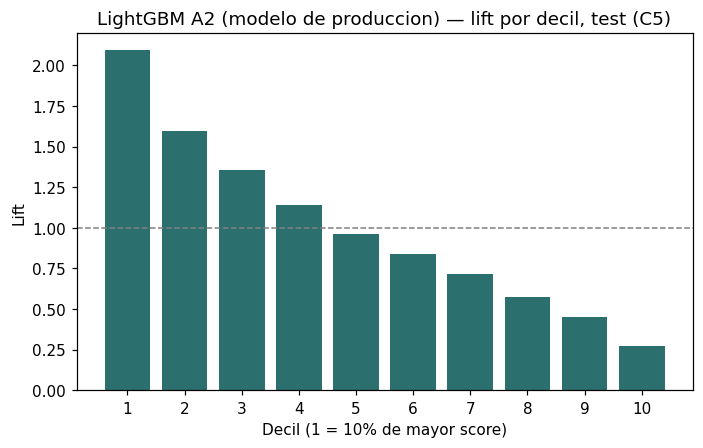

In [3]:
def lift_por_decil(y_true, score):
    dec = pd.qcut(pd.Series(score).rank(method="first"), 10, labels=False)
    t = pd.DataFrame({"y": y_true, "decil": 9 - dec})  # decil 0 = mayor score
    base = y_true.mean()
    g = t.groupby("decil")["y"].agg(["size", "mean"])
    g["lift"] = g["mean"] / base
    return g.sort_index()

decil_te = lift_por_decil(y_te, score_te)
print(decil_te.round(3).to_string())

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.bar(decil_te.index + 1, decil_te["lift"], color="#2b6f6f")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Decil (1 = 10% de mayor score)")
ax.set_ylabel("Lift")
ax.set_title("LightGBM A2 (modelo de produccion) — lift por decil, test (C5)")
ax.set_xticks(range(1, 11))
plt.tight_layout()
fig.savefig(DIR_RES / "figures" / "lift_por_decil_lgbm_final.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nguardado en results/figures/lift_por_decil_lgbm_final.png")


**Lectura:** el lift cae de forma monótona del decil 1 al 10 (sin inversiones), lo que confirma que el score ordena de forma consistente y no solo acierta en el extremo superior — importante porque Marketing puede ajustar el tamaño de la lista (k) sin perder la propiedad de ordenamiento.

In [4]:
ctrl = pd.read_parquet(DIR_DAT / "ds_entrenable.parquet")
ctrl_te = ctrl.loc[ctrl["split"] == "test"].reset_index(drop=True)

# verificacion de alineacion fila a fila entre el control (ds_entrenable) y
# las features de test (XA2_test) antes de usar columnas de control ajenas a X
assert len(ctrl_te) == len(XA2_te), "tamanos distintos, no se puede alinear"
assert np.allclose(ctrl_te["recency_dias"].to_numpy(), XA2_te["recency_dias"].to_numpy()), \
    "el orden de filas no coincide entre ds_entrenable(test) y XA2_test"
print("OK: ds_entrenable(test) y XA2_test estan alineados fila a fila.\n")

te_ctrl = ctrl_te[["segmento_frecuencia", "es_comprador_cronico"]].copy()
te_ctrl["score"] = score_te
te_ctrl["y"] = y_te

def desglose(col):
    filas = []
    for val, g in te_ctrl.groupby(col, observed=True):
        from sklearn.metrics import average_precision_score
        filas.append({
            col: val, "n": len(g), "tasa_base": g["y"].mean(),
            "pr_auc": average_precision_score(g["y"], g["score"]),
            "precision@10%": precision_en_k(g["y"].to_numpy(), g["score"].to_numpy(), 0.10),
            "lift@10%": lift_en_k(g["y"].to_numpy(), g["score"].to_numpy(), 0.10),
        })
    return pd.DataFrame(filas).round(4)

seg = desglose("segmento_frecuencia")
cro = desglose("es_comprador_cronico")
print("-- por segmento de frecuencia --")
print(seg.to_string(index=False))
print("\n-- por comprador cronico --")
print(cro.to_string(index=False))

seg.to_csv(DIR_RES / "metrics" / "desglose_segmento_test_final.csv", index=False)
cro.to_csv(DIR_RES / "metrics" / "desglose_cronico_test_final.csv", index=False)


OK: ds_entrenable(test) y XA2_test estan alineados fila a fila.

-- por segmento de frecuencia --
segmento_frecuencia     n  tasa_base  pr_auc  precision@10%  lift@10%
            1. baja 21090     0.5716  0.7733         0.9137    1.5986
           2. media 21398     0.3827  0.6102         0.7509    1.9624
            3. alta 23933     0.2685  0.5504         0.6841    2.5482

-- por comprador cronico --
 es_comprador_cronico     n  tasa_base  pr_auc  precision@10%  lift@10%
                    0 65791     0.4010  0.6867         0.8398    2.0942
                    1   630     0.4508  0.7458         0.8571    1.9014


**Lectura (regla no negociable: métricas siempre desglosadas por segmento y por comprador crónico):** el PR-AUC absoluto es mayor en el segmento de baja frecuencia (0.77) porque su tasa base de churn también es más alta, pero el **lift@10% es mayor en el segmento de alta frecuencia** (2.55 vs. 1.60 en baja) — el modelo discrimina mejor en términos relativos dentro de los clientes frecuentes. En comprador crónico la muestra es muy chica (630 clientes de test, 0.9%), así que el PR-AUC=0.75 de ese grupo se reporta con cautela, no como conclusión firme.

## Explicabilidad con SHAP (T3.7)

Criterio de aceptación: *"para un cliente cualquiera se puede explicar en una frase por qué está en riesgo. Marketing no adopta una lista que no entiende."* Se usa `TreeExplainer` sobre el modelo LightGBM de producción, calculado sobre una muestra de 4.000 clientes de **validación** (no de test: esto es exploración de por qué el modelo decide lo que decide, no una nueva evaluación de desempeño).

                     feature  shap_abs_medio
                recency_dias          0.5611
          umbral_propio_dias          0.2964
           n_dias_activo_12m          0.2243
             tendencia_gasto          0.1550
               n_visitas_12m          0.0616
            antiguedad_meses          0.0484
     n_bodegas_distintas_12m          0.0446
             monto_total_12m          0.0174
n_metodos_pago_distintos_12m          0.0113
             ticket_promedio          0.0043
   metodo_pago_principal_12m          0.0040
  n_categorias_distintas_12m          0.0026
       pct_gasto_cronico_12m          0.0025
        es_comprador_cronico          0.0000


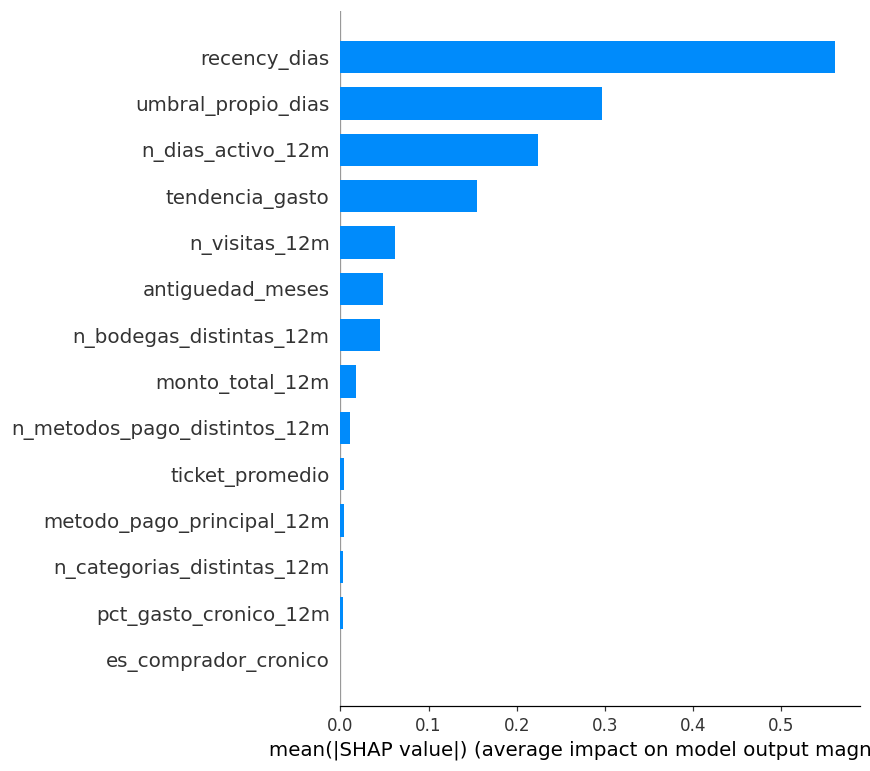

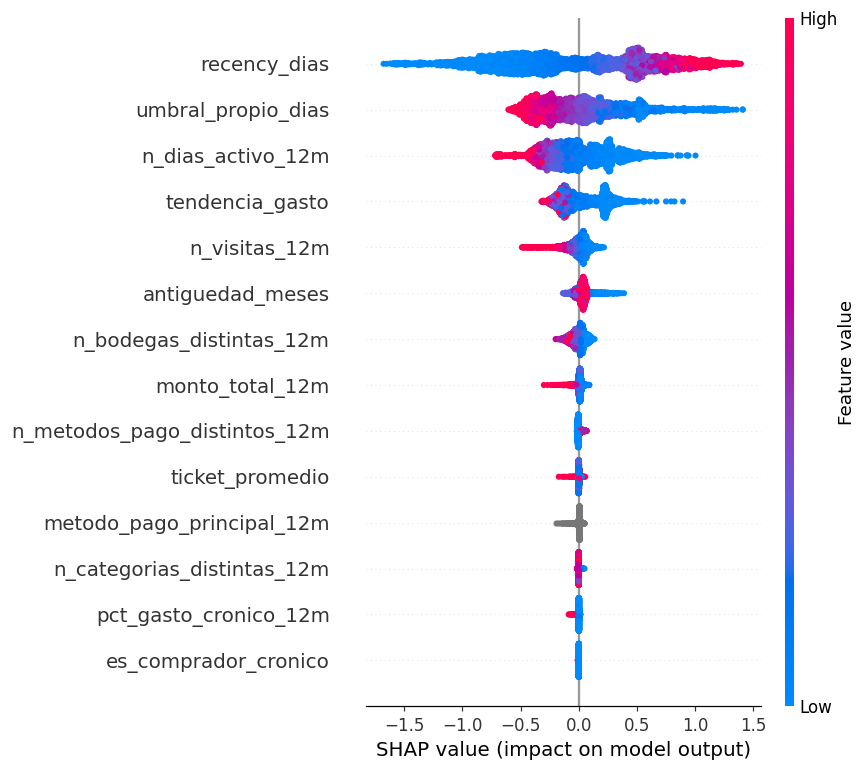

In [5]:
import shap

muestra = XA2_va.sample(n=4000, random_state=42)
explainer = shap.TreeExplainer(modelo_lgbm)
sv = explainer(muestra)

imp = pd.DataFrame({"feature": muestra.columns, "shap_abs_medio": np.abs(sv.values).mean(axis=0)})
imp = imp.sort_values("shap_abs_medio", ascending=False)
print(imp.round(4).to_string(index=False))
imp.to_csv(DIR_RES / "metrics" / "shap_importancia_lgbm_final.csv", index=False)

plt.figure(); shap.summary_plot(sv, muestra, show=False, plot_type="bar", max_display=14); plt.tight_layout()
plt.savefig(DIR_RES / "figures" / "shap_bar_final.png", dpi=150, bbox_inches="tight"); plt.show()
plt.figure(); shap.summary_plot(sv, muestra, show=False, max_display=14); plt.tight_layout()
plt.savefig(DIR_RES / "figures" / "shap_beeswarm_final.png", dpi=150, bbox_inches="tight"); plt.show()


**Lectura de negocio:** `recency_dias` domina con claridad (el doble de importancia que la siguiente), seguido de `umbral_propio_dias` (consistente con el análisis de sensibilidad de `04_optimizacion.ipynb`: aporta, pero no es lo único) y `n_dias_activo_12m`. **Hallazgo a declarar:** `es_comprador_cronico` y `pct_gasto_cronico_12m` — las dos features diseñadas específicamente para distinguir fuga comercial de interrupción de tratamiento (ver limitación #4 de `CONTEXTO_PROYECTO.md`) — tienen importancia casi nula. El modelo no se apoya en ellas para ordenar el riesgo; **no** resuelve la limitación de confundir deserción con fin de tratamiento, solo la declara, sin poder corregirla con las features actuales.

### Dos ejemplos individuales (para conversar con Marketing)

alto_riesgo: probabilidad de churn = 0.920
bajo_riesgo: probabilidad de churn = 0.047


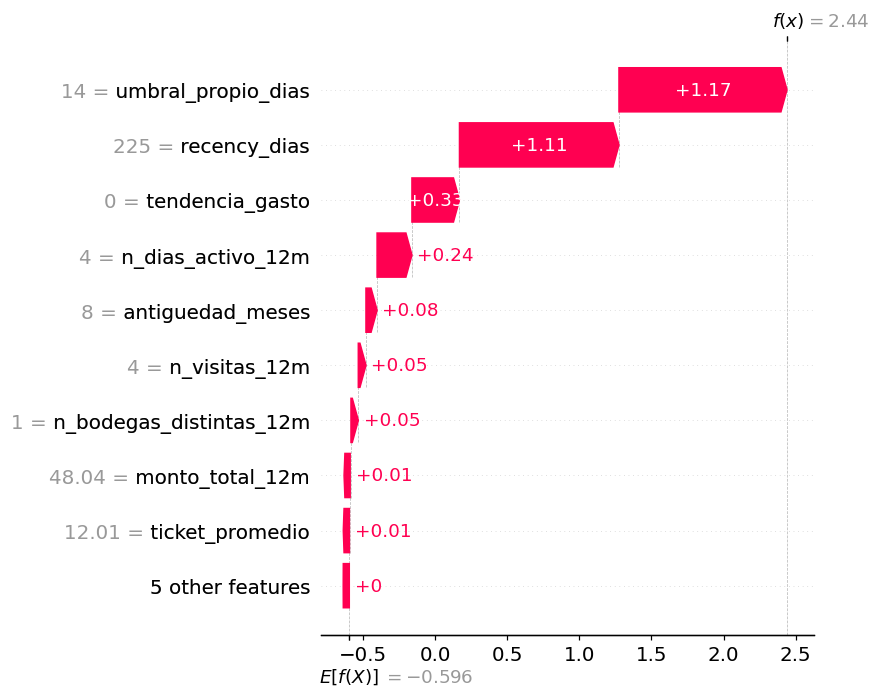

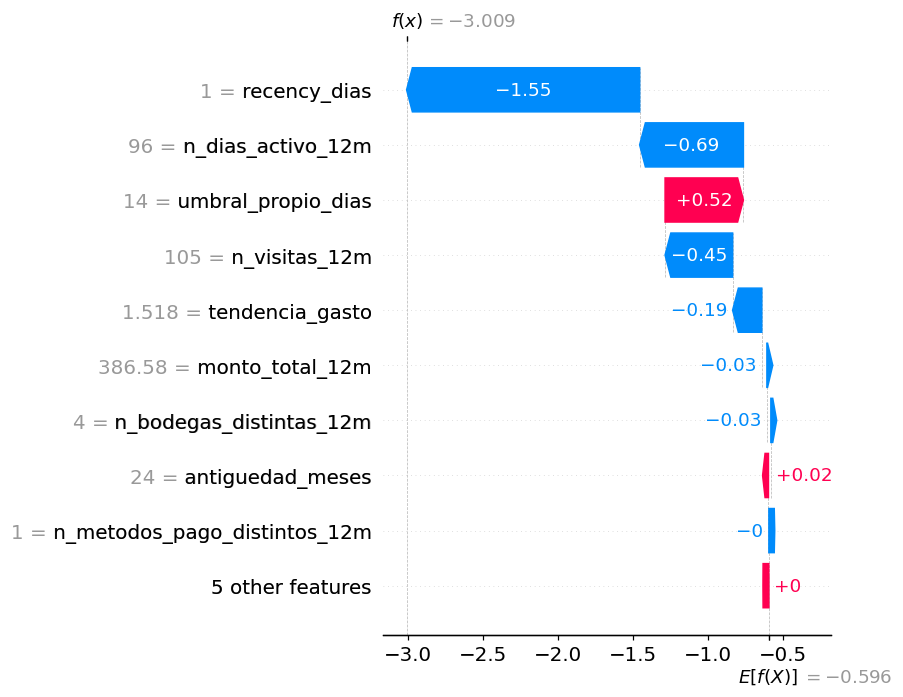

In [6]:
p_va = modelo_lgbm.predict_proba(XA2_va)[:, 1]
idx_alto = int(np.argsort(-p_va)[100])   # alto riesgo, evitando el outlier extremo
idx_bajo = int(np.argsort(p_va)[100])    # bajo riesgo

for tag, idx in [("alto_riesgo", idx_alto), ("bajo_riesgo", idx_bajo)]:
    fila = XA2_va.iloc[[idx]]
    sv1 = explainer(fila)
    plt.figure(); shap.plots.waterfall(sv1[0], show=False, max_display=10); plt.tight_layout()
    plt.savefig(DIR_RES / f"figures/shap_waterfall_{tag}_final.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"{tag}: probabilidad de churn = {p_va[idx]:.3f}")


**Cliente de alto riesgo:** su `umbral_propio_dias` es de solo 14 días (el piso mínimo posible: compra con mucha regularidad) pero lleva muchos más días sin comprar que su propio ritmo esperado. En una frase: *"este cliente compra típicamente cada dos semanas y lleva varios meses sin volver."*

**Cliente de bajo riesgo:** compró muy recientemente, con muchos días activos y visitas en los últimos 12 meses. En una frase: *"cliente muy activo que acaba de comprar; nada indica que vaya a desaparecer."*

## Conclusión

**Modelo de producción: LightGBM (A2, categóricas nativas)**, guardado en `models/best_model.pkl`. Supera con claridad a los baselines (nivel 0/1) y a la regresión logística (nivel 2) en PR-AUC y en las seis métricas de precision@k/lift, pasa el análisis de sensibilidad de `umbral_propio_dias` (`04_optimizacion.ipynb`, T3.4 — no memoriza la regla de etiquetado) y es explicable con SHAP a nivel individual (T3.7).

**Pendiente antes de considerar cerrada la Fase 3 de `PLAN_DE_ACCION.md`:**

- **T3.5 — Calibración.** Las probabilidades de `predict_proba` ordenan bien (ver lift por decil) pero no están garantizadas como calibradas; hace falta Platt scaling o isotonic regression con curva de confiabilidad y Brier score antes de fijar un umbral de probabilidad para decidir a quién contactar.
- **T3.8 — Análisis de supervivencia.** El diferenciador académico del trabajo: incorporar los clientes censurados (15.82% del total) como información parcial en vez de excluirlos, y responder "¿cuándo?" y no solo "¿sí o no?".

Ver `docs/optimizacion.md` para el detalle de la búsqueda de hiperparámetros y la decisión A1 vs. A2, y `docs/arquitectura.md` para el diseño completo del modelo.